# AutoResearchForecaster

![AutoResearch overview](imgs/autoresearch.webp)

In this notebook we use `AutoResearchForecaster`, an LLM-assisted forecaster that searches over ordinary sktime forecasting blueprints.

By the end, you should have seen:

- how an LLM proposes sktime estimator blueprints;
- how `craft()` turns those blueprints into real sktime objects;
- how sktime evaluates the candidates;
- how to inspect the selected model and the search trace.

Credit: this work builds on Benedikt Heidrich's `AutoResearchForecaster` and his post [LLM Driven AutoForecasting with Sktime's `craft()`](https://medium.com/towards-artificial-intelligence/llm-driven-autoforecasting-with-sktimes-craft-0355f5c720e8).

## The idea

A forecasting workflow often starts with expert judgement:

- inspect the data;
- choose a few plausible models;
- evaluate them;
- refine the next attempt.

`AutoResearchForecaster` puts that loop inside an sktime estimator.

The LLM writes candidate sktime model specifications. sktime builds and evaluates them.

In [1]:
import warnings

warnings.filterwarnings("ignore")
warnings.simplefilter("ignore")

In [1]:
import litellm
from litellm.caching.caching import Cache

litellm.cache = Cache(type="local")

## Constructor parameters

The constructor sets how the search runs during `fit`.

```python
AutoResearchForecaster(
    cv=cv,
    model="openai/gpt-4o-mini",      # any LiteLLM model string
    n_iterations=3,
    n_blueprints=5,
    n_fix_attempts=0,
    api_params={"temperature": 0.3},
    description_method="basic",      # "basic", "described_plot", "image"
    estimator_info="names",          # "names", "signatures", "docstrings"
)
```

| parameter | role |
|---|---|
| `cv` | Validation splitter used to score each proposed blueprint. This is the main definition of "best". |
| `model` | LLM identifier passed to LiteLLM, for example `openai/gpt-4o-mini`. |
| `n_iterations` | Number of propose → evaluate → refine rounds. More rounds mean more LLM calls and more candidate fits. |
| `n_blueprints` | Number of candidate blueprints requested from the LLM per round. |
| `n_fix_attempts` | Extra LLM repair attempts for blueprints that fail to instantiate or evaluate. |
| `api_params` | Extra arguments for `litellm.completion`, such as `temperature`, `max_tokens`, or caching options. |
| `description_method` | How the time series is described to the LLM: text statistics, a VLM-generated plot description, or the plot image. |
| `estimator_info` | How much registry information is included in the prompt: estimator names, constructor signatures, or docstrings. |
| `system_prompt` | Your own first prompt, instead of the default. |
| `refinement_prompt` | Your own prompt for the refinement rounds. |
| `llm_func` | Controls how the LLM is called: replace LiteLLM with another SDK or a local model, or skip the LLM entirely with a mock. Returns the blueprints as JSON text. |

Smaller `n_iterations` and `n_blueprints` run faster. `cv` decides the quality of the selection.

In [3]:
MODEL = "openai/gpt-4o-mini"
API_PARAMS = {
    "temperature": 0.3,
    "caching": True,
    # "api_key": ...,
}

## How `craft()` works

`craft()` takes a string that looks like an sktime constructor call and returns the estimator.

For example, the LLM can propose:

```python
'NaiveForecaster(strategy="last", sp=12)'
```

or a full pipeline:

```python
'TransformedTargetForecaster([Deseasonalizer(sp=12), Detrender(), NaiveForecaster(strategy="drift")])'
```

The LLM only writes text. sktime builds and evaluates the estimator.

In [4]:
from sktime.registry import craft

blueprint_spec = 'NaiveForecaster(strategy="last", sp=12)'
craft(blueprint_spec)

NaiveForecaster(sp=12)

## The search loop

One iteration of `AutoResearchForecaster` looks like this:

1. The LLM proposes several blueprint objects.
2. Each `spec` is built with `craft()`.
3. sktime evaluates each candidate on the supplied `cv` splitter.
4. Scores and errors are fed back to the LLM.
5. The next iteration proposes refined candidates.

A candidate blueprint could look like:

```json
{
  "name": "Seasonal ETS",
  "spec": "ExponentialSmoothing(trend='add', seasonal='add', sp=12)",
  "reason": "monthly data often has yearly seasonality"
}
```

Another could be:

```json
{
  "name": "Deseasonalized drift",
  "spec": "TransformedTargetForecaster([Deseasonalizer(sp=12), NaiveForecaster(strategy='drift')])",
  "reason": "remove yearly seasonality, then extrapolate trend"
}
```

## Refinement

Each new prompt includes the results of the previous round.

Example after one round:

| blueprint | outcome |
|---|---|
| Seasonal ETS | MAPE = 0.18 |
| Deseasonalized drift | MAPE = 0.24 |
| BoxCox + ETS | failed: invalid constructor argument |

The next LLM call can then:

- keep the seasonal idea because it scored best;
- try a simpler seasonal baseline;
- fix the failed constructor;
- propose one new alternative.

At the end, the best successful blueprint is refit on the full training data.

## Case study: monthly tourism

We will use one monthly tourism series from the workshop data.

The series has enough history for rolling validation, and a monthly horizon makes seasonal candidates natural.

The CSV holds 284 series but for simplicity we pick one and give it a monthly index.

In [2]:
import pandas as pd
from sktime.utils.plotting import plot_series

from tourism import load_tourism


y = load_tourism(region="Central NSW", purpose="Holiday")

y.head(), y.tail(), len(y)

(Period
 1998-01    1038.514682
 1998-02    1135.283222
 1998-03    1575.363560
 1998-04     587.236535
 1998-05     557.744683
 Freq: M, Name: Central NSW holiday trips, dtype: float64,
 Period
 2016-08    668.745864
 2016-09    324.079217
 2016-10    487.830382
 2016-11    390.971637
 2016-12    526.264080
 Freq: M, Name: Central NSW holiday trips, dtype: float64,
 228)

(<Figure size 1600x400 with 1 Axes>,
 <Axes: ylabel='Central NSW holiday trips'>)

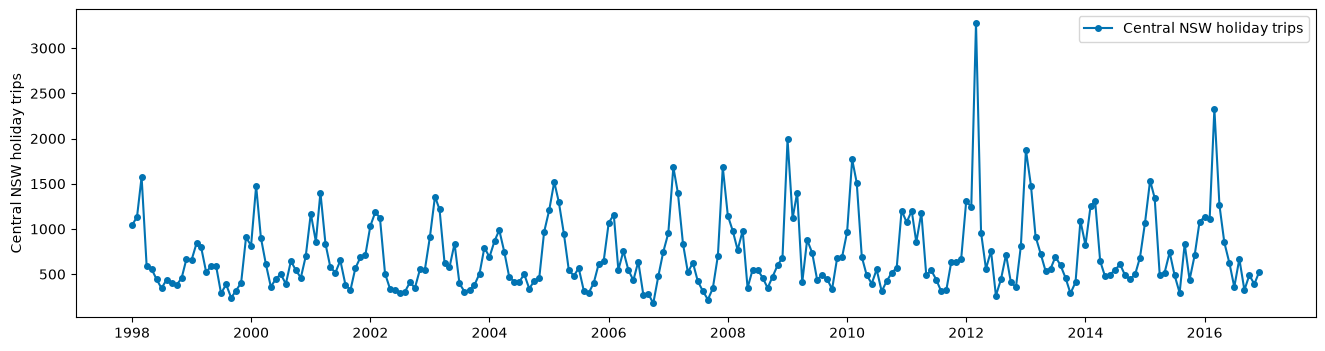

In [3]:
plot_series(y, labels=["Central NSW holiday trips"])

## Fit AutoResearchForecaster

This cell runs the actual research loop.

There is no separate `verbose` switch in the current implementation. During `fit`, it prints the iterations and candidate scores. After fitting, the persistent trace is available through `blueprint_history_` and `summary()`.

In [7]:
from sktime.forecasting.agentic import AutoResearchForecaster
from sktime.split import ExpandingWindowSplitter, temporal_train_test_split

y_train, y_test = temporal_train_test_split(y, test_size=12)
fh = list(range(1, 13))

cv = ExpandingWindowSplitter(
    fh=fh,
    initial_window=120,
    step_length=12,
)

auto = AutoResearchForecaster(
    cv=cv,
    model=MODEL,
    n_iterations=2,
    n_blueprints=4,
    n_fix_attempts=1,
    api_params=API_PARAMS,
    description_method="basic",
    estimator_info="names",
)

auto.fit(y_train, fh=fh)

Iteration 1/2
  Generating blueprints via LLM...
    Naive mean: Score=0.421217
    Differencer + AutoETS: Score=0.693800
    Deseasonalizer + ARIMA: Score=0.219506
    BoxCox + Exponential Smoothing: FAILED (TypeError: BoxCoxTransformer.__init__() got an unexpected keyword argument 'lmbda')
Trying to fix 'BoxCox + Exponential Smoothing', retry: 1
      [fix attempt 1] BoxCox + Exponential Smoothing: Score=nan
  Best this iteration: Deseasonalizer + ARIMA (Score: 0.219506)
Iteration 2/2
  Generating blueprints via LLM...
    Deseasonalizer + ARIMA with Differencing: Score=0.445266
    Differencer + AutoARIMA: Score=0.737369
    Fixed BoxCox + Exponential Smoothing: Score=nan
    Lag + AutoETS: Score=0.719691
  Best this iteration: Deseasonalizer + ARIMA with Differencing (Score: 0.445266)


AutoResearchForecaster(api_params={'caching': True, 'temperature': 0.3},
                       cv=ExpandingWindowSplitter(fh=[1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                      10, 11, 12],
                                                  initial_window=120,
                                                  step_length=12),
                       n_blueprints=4, n_fix_attempts=1, n_iterations=2)

## Forecast

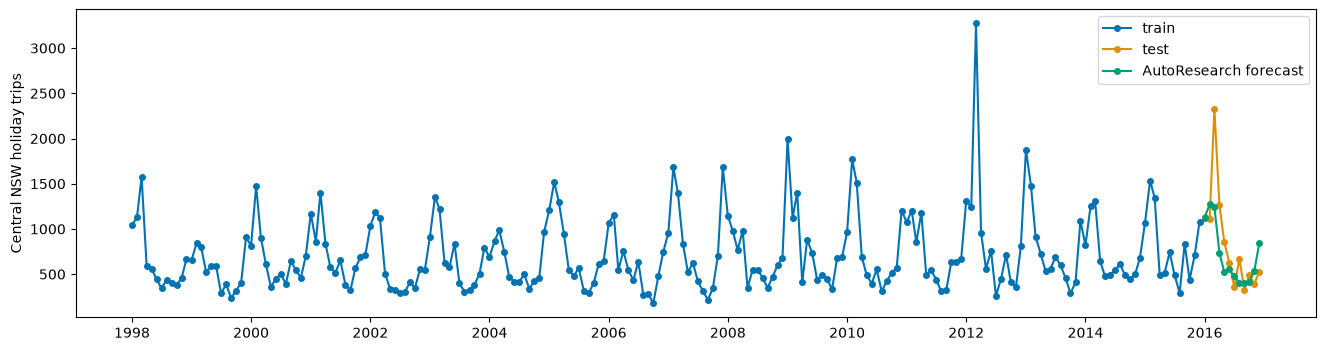

In [8]:
y_pred = auto.predict(fh=fh)

plot_series(
    y_train,
    y_test,
    y_pred,
    labels=["train", "test", "AutoResearch forecast"],
);

## Selected blueprint

This is the model specification selected by the search.

In [9]:
auto.best_blueprint_

{'name': 'Deseasonalizer + ARIMA',
 'spec': 'TransformedTargetForecaster([Deseasonalizer(sp=12), ARIMA()])',
 'reason': 'Deseasonalizing the data first allows ARIMA to model the underlying trend more effectively without seasonal noise.'}

## Selected estimator representation

The estimator repr is often easier to inspect than a truncated table cell.

In [10]:
auto.best_forecaster_

TransformedTargetForecaster(steps=[Deseasonalizer(sp=12), ARIMA()])

In [11]:
print(auto.best_forecaster_)

TransformedTargetForecaster(steps=[Deseasonalizer(sp=12), ARIMA()])


## Search trace

This table shows the full sequence of evaluated blueprints. The `spec` column is intentionally left untruncated.

In [12]:
history = pd.DataFrame(
    [
        {
            "name": result["name"],
            "score": result["score"] if result["error"] is None else None,
            "error": result["error"],
            "spec": result["blueprint"].get("spec", ""),
        }
        for result in auto.blueprint_history_
    ]
)

history

,name,score,error,spec
0,Naive mean,0.421217,None,"NaiveForecaster(strategy=""mean"")"
1,Differencer + AutoETS,0.693800,None,"TransformedTargetForecaster([Differencer(), AutoETS()])"
2,Deseasonalizer + ARIMA,0.219506,None,"TransformedTargetForecaster([Deseasonalizer(sp=12), ARIMA()])"
3,BoxCox + Exponential Smoothing,NaN,TypeError: BoxCoxTransformer.__init__() got an unexpected keyword argument 'lmbda',"TransformedTargetForecaster([BoxCoxTransformer(lmbda=0.5), ExponentialSmoothing(trend=""add"", seasonal=""add"", sp=12)])"
4,BoxCox + Exponential Smoothing,NaN,None,"TransformedTargetForecaster([BoxCoxTransformer(method=""pearsonr""), ExponentialSmoothing(trend=""add"", seasonal=""add"", sp=12)])"
5,Deseasonalizer + ARIMA with Differencing,0.445266,None,"TransformedTargetForecaster([Deseasonalizer(sp=12), Differencer(), ARIMA()])"
6,Differencer + AutoARIMA,0.737369,None,"TransformedTargetForecaster([Differencer(), AutoARIMA()])"
7,Fixed BoxCox + Exponential Smoothing,NaN,None,"TransformedTargetForecaster([BoxCoxTransformer(method=""pearsonr""), ExponentialSmoothing(trend=""add"", seasonal=""add"", sp=12)])"
8,Lag + AutoETS,0.719691,None,"TransformedTargetForecaster([Lag(), AutoETS()])"


## Ranked blueprints

`summary()` gives a ranked view of all candidates and keeps failed candidates visible.

In [13]:
summary = auto.summary()
summary[["name", "score", "error", "spec"]]

,name,score,error,spec
2,Deseasonalizer + ARIMA,0.219506,None,"TransformedTargetForecaster([Deseasonalizer(sp=12), ARIMA()])"
0,Naive mean,0.421217,None,"NaiveForecaster(strategy=""mean"")"
5,Deseasonalizer + ARIMA with Differencing,0.445266,None,"TransformedTargetForecaster([Deseasonalizer(sp=12), Differencer(), ARIMA()])"
1,Differencer + AutoETS,0.693800,None,"TransformedTargetForecaster([Differencer(), AutoETS()])"
8,Lag + AutoETS,0.719691,None,"TransformedTargetForecaster([Lag(), AutoETS()])"
6,Differencer + AutoARIMA,0.737369,None,"TransformedTargetForecaster([Differencer(), AutoARIMA()])"
3,BoxCox + Exponential Smoothing,NaN,TypeError: BoxCoxTransformer.__init__() got an unexpected keyword argument 'lmbda',"TransformedTargetForecaster([BoxCoxTransformer(lmbda=0.5), ExponentialSmoothing(trend=""add"", seasonal=""add"", sp=12)])"
4,BoxCox + Exponential Smoothing,NaN,None,"TransformedTargetForecaster([BoxCoxTransformer(method=""pearsonr""), ExponentialSmoothing(trend=""add"", seasonal=""add"", sp=12)])"
7,Fixed BoxCox + Exponential Smoothing,NaN,None,"TransformedTargetForecaster([BoxCoxTransformer(method=""pearsonr""), ExponentialSmoothing(trend=""add"", seasonal=""add"", sp=12)])"


## Baseline check

Auto-research is still model selection. We should compare it with a simple baseline.

In [14]:
from sktime.forecasting.naive import NaiveForecaster
from sktime.performance_metrics.forecasting import mean_absolute_percentage_error

seasonal_naive = NaiveForecaster(strategy="last", sp=12)
seasonal_naive.fit(y_train, fh=fh)
y_pred_naive = seasonal_naive.predict(fh=fh)

pd.DataFrame(
    {
        "model": ["seasonal naive", "AutoResearch selected"],
        "MAPE": [
            mean_absolute_percentage_error(y_test, y_pred_naive),
            mean_absolute_percentage_error(y_test, y_pred),
        ],
    }
)

,model,MAPE
0,seasonal naive,0.542998
1,AutoResearch selected,0.300554


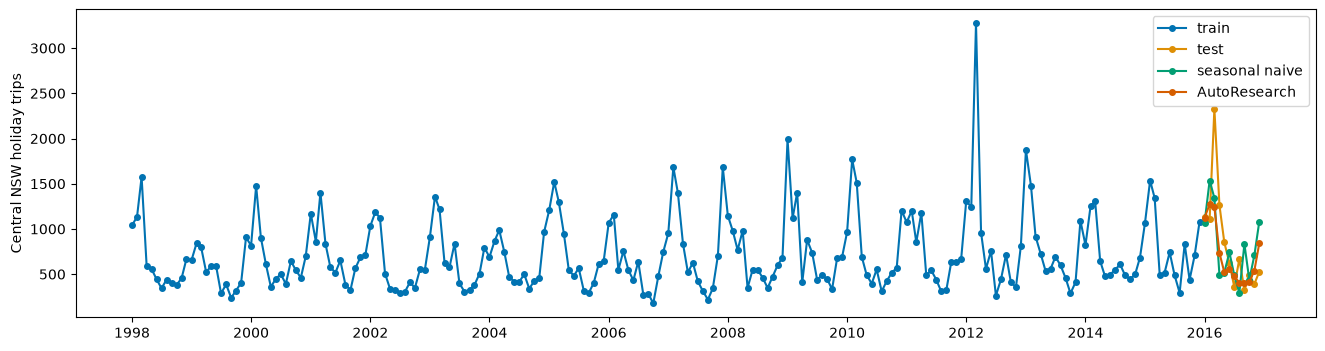

In [15]:
plot_series(
    y_train,
    y_test,
    y_pred_naive,
    y_pred,
    labels=["train", "test", "seasonal naive", "AutoResearch"],
);

## Summary

What we saw:

- `craft()` converts LLM-generated blueprint strings into sktime estimators.
- `AutoResearchForecaster` runs a propose/evaluate/refine loop.
- The validation splitter decides how candidates are judged.
- `fit()` shows iteration progress.
- `blueprint_history_`, `summary()`, and the estimator repr make the result inspectable.
- The final selected model is still an ordinary sktime forecaster.

What to keep in mind:

- LLMs can propose invalid or expensive candidates.
- The search is only as good as the validation design.
- Use it as an assistant. Still check baselines and model behavior.

## Up next: Implementing your own estimators using agents and sktime
LLM helped choose a good estimator, but what if you want to implement your own estimator (and contribute to sktime!)

- Next: implement your own, with or without agents
- Possible because every sktime estimator shares one interface
- Two tools: extension templates, skills